# Athlete Training-Load Decision Support System (DSS)
**Course:** Decision Support Systems — Group Project
**Dataset:** `sports_performance_data.csv` (12,600 records, 21 columns)

**Decision supported:** each week a coach decides what to do with an athlete's training load —
**Increase / Maintain / Reduce / Rest & medical check**.

**DSS type:** Hybrid
- *Model-driven* — an ML model predicts the athlete's expected performance.
- *Knowledge-driven* — sports-science rules score readiness and injury risk.
- *Data-driven* — athlete data feeds both and is shown on a dashboard.

**Notebook structure**
1. Data audit  2. Cleaning  3. Exploratory analysis  4. ML model  5. DSS decision layer  6. Scenario evaluation  7. Export

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import joblib, warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

df_raw = pd.read_csv('sports_performance_data.csv')
print(df_raw.shape)
df_raw.head()

(12600, 21)


,Athlete_ID,Athlete_Name,Sport_Type,Event,Training_Hours_per_Week,Average_Heart_Rate,BMI,Sleep_Hours_per_Night,Daily_Caloric_Intake,Hydration_Level,...,Previous_Competition_Performance,Training_Intensity,Resting_Heart_Rate,Body_Fat_Percentage,VO2_Max,Event_Distance,Altitude_Training,Mental_Focus_Level,Competition_Date,Performance_Metric
0,A754,Athlete_15,Running,50m Freestyle,18.11,192.6,29.6,7.6,1890.0,57.8,...,5.81,Low,92.0,20.0,65.4,151.89,Low,9.7,2024-05-29,83.24
1,A792,Athlete_95,Soccer,NaN,12.43,77.3,18.7,NaN,2811.9,71.6,...,29.12,Medium,76.7,8.5,44.6,1863.49,NaN,5.1,2024-07-05,78.52
2,A195,Athlete_28,Swimming,100m Sprint,11.99,127.1,26.8,NaN,3018.9,58.5,...,6.51,Low,96.9,29.1,70.4,1557.84,High,1.9,2024-03-30,68.42
3,A559,Athlete_76,Cycling,100m Sprint,20.41,68.3,24.9,4.2,3773.3,62.9,...,66.25,High,NaN,18.0,57.3,965.03,High,9.7,2024-01-28,77.51
4,A384,Athlete_20,Swimming,50m Freestyle,37.88,184.2,27.0,9.5,1721.2,59.8,...,4.52,Low,59.5,14.7,43.6,4152.25,High,4.2,2024-06-01,NaN


## 1. Data audit
Before modelling we check missing values, duplicates and logical consistency.

In [2]:
audit = pd.DataFrame({'dtype': df_raw.dtypes.astype(str),
                      'missing_%': (df_raw.isna().mean()*100).round(1),
                      'unique': df_raw.nunique()})
print('Exact duplicate rows:', df_raw.duplicated().sum())
audit

Exact duplicate rows: 600


,dtype,missing_%,unique
Athlete_ID,str,5.0,900
Athlete_Name,str,5.0,100
Sport_Type,str,5.0,6
Event,str,5.1,4
Training_Hours_per_Week,float64,5.0,3368
Average_Heart_Rate,float64,5.0,1501
BMI,float64,5.0,201
Sleep_Hours_per_Night,float64,5.0,61
Daily_Caloric_Intake,float64,5.1,9155
Hydration_Level,float64,5.1,501


In [3]:
# Categorical columns: how much is missing?
for c in ['Injury_History', 'Altitude_Training', 'Training_Intensity']:
    print(c, df_raw[c].value_counts(dropna=False, normalize=True).round(3).to_dict())

Injury_History {nan: 0.374, 'Major': 0.313, 'Minor': 0.312}
Altitude_Training {nan: 0.288, 'High': 0.244, 'Medium': 0.236, 'Low': 0.232}
Training_Intensity {'Medium': 0.32, 'Low': 0.315, 'High': 0.314, nan: 0.051}


**Finding — "missing" sometimes means "none".** Most columns are ~5 % empty, but `Injury_History`
is 37 % empty and `Altitude_Training` 29 %. The categories are otherwise balanced (Major 31 % / Minor 31 %;
High/Medium/Low ≈ 24 % each), so the extra ~32 % / ~24 % is very likely athletes with **no injury** /
**no altitude training**. We encode these as a `None` category instead of imputing them.

In [4]:
# Consistency checks
print('Sport vs Event cross-tab:')
display(pd.crosstab(df_raw.Sport_Type, df_raw.Event))
print('Distinct sports per Athlete_ID:')
print(df_raw.groupby('Athlete_ID').Sport_Type.nunique().describe().round(2))

Sport vs Event cross-tab:


Event,100m Sprint,10km Road Race,50m Freestyle,Marathon
Sport_Type,,,,
Basketball,503,453,459,494
Cycling,465,454,460,447
Running,410,517,480,479
Soccer,477,462,427,507
Swimming,480,474,472,473
Tennis,454,493,495,522


Distinct sports per Athlete_ID:
count    900.00
mean       5.24
std        0.83
min        2.00
25%        5.00
50%        5.00
75%        6.00
max        6.00
Name: Sport_Type, dtype: float64


**Finding — inconsistencies.**
- `Event` does not match `Sport_Type` (e.g. Basketball players in *50m Freestyle*, Soccer players in *Marathon*).
  The event column is unreliable, so it is **dropped**; `Event_Distance` is kept as a numeric load indicator.
- One `Athlete_ID` appears under ~5 different sports, so IDs are not stable athletes.
  We treat **each row as one athlete-week record**.

These are limitations to mention in the report's *Evaluation* and *Reflection* sections.

## 2. Cleaning

In [5]:
df = df_raw.drop_duplicates().copy()
df = df.dropna(subset=['Performance_Metric'])          # target must be known
df['Injury_History'] = df['Injury_History'].fillna('None')
df['Altitude_Training'] = df['Altitude_Training'].fillna('None')
df = df.drop(columns=['Event', 'Athlete_Name'])
df['Competition_Date'] = pd.to_datetime(df['Competition_Date'], errors='coerce')

num_cols = ['Training_Hours_per_Week','Average_Heart_Rate','BMI','Sleep_Hours_per_Night',
            'Daily_Caloric_Intake','Hydration_Level','Previous_Competition_Performance',
            'Resting_Heart_Rate','Body_Fat_Percentage','VO2_Max','Event_Distance','Mental_Focus_Level']
cat_cols = ['Sport_Type','Training_Intensity','Injury_History','Altitude_Training']

# Remaining ~5% gaps: numeric -> median within the same sport, categorical -> mode
df['Sport_Type'] = df['Sport_Type'].fillna('Unknown')
for c in num_cols:
    df[c] = df.groupby('Sport_Type')[c].transform(lambda s: s.fillna(s.median()))
df['Training_Intensity'] = df['Training_Intensity'].fillna(df['Training_Intensity'].mode()[0])

print('Rows: raw', len(df_raw), '-> clean', len(df))
print('Remaining missing values:', df[num_cols+cat_cols].isna().sum().sum())

Rows: raw 12600 -> clean 11400
Remaining missing values: 0


## 3. Exploratory analysis

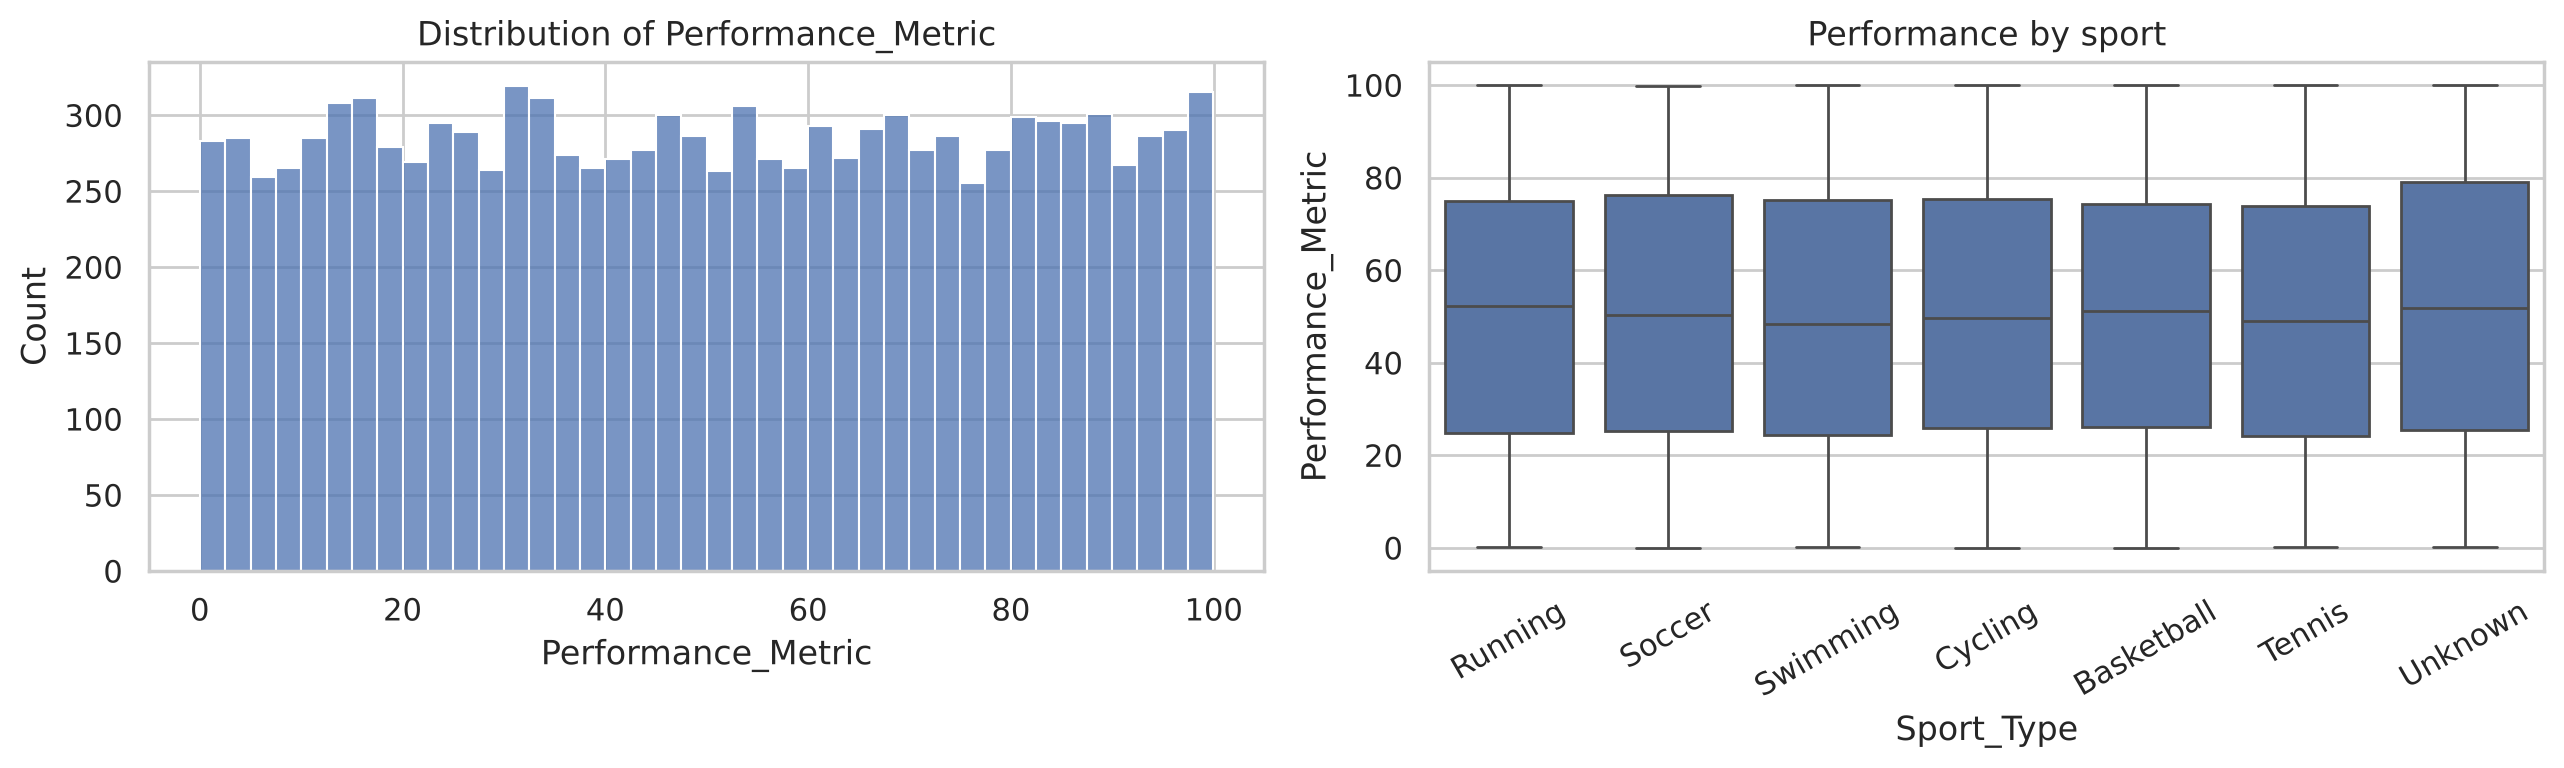

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.Performance_Metric, bins=40, ax=ax[0]).set_title('Distribution of Performance_Metric')
sns.boxplot(data=df, x='Sport_Type', y='Performance_Metric', ax=ax[1]).set_title('Performance by sport')
ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

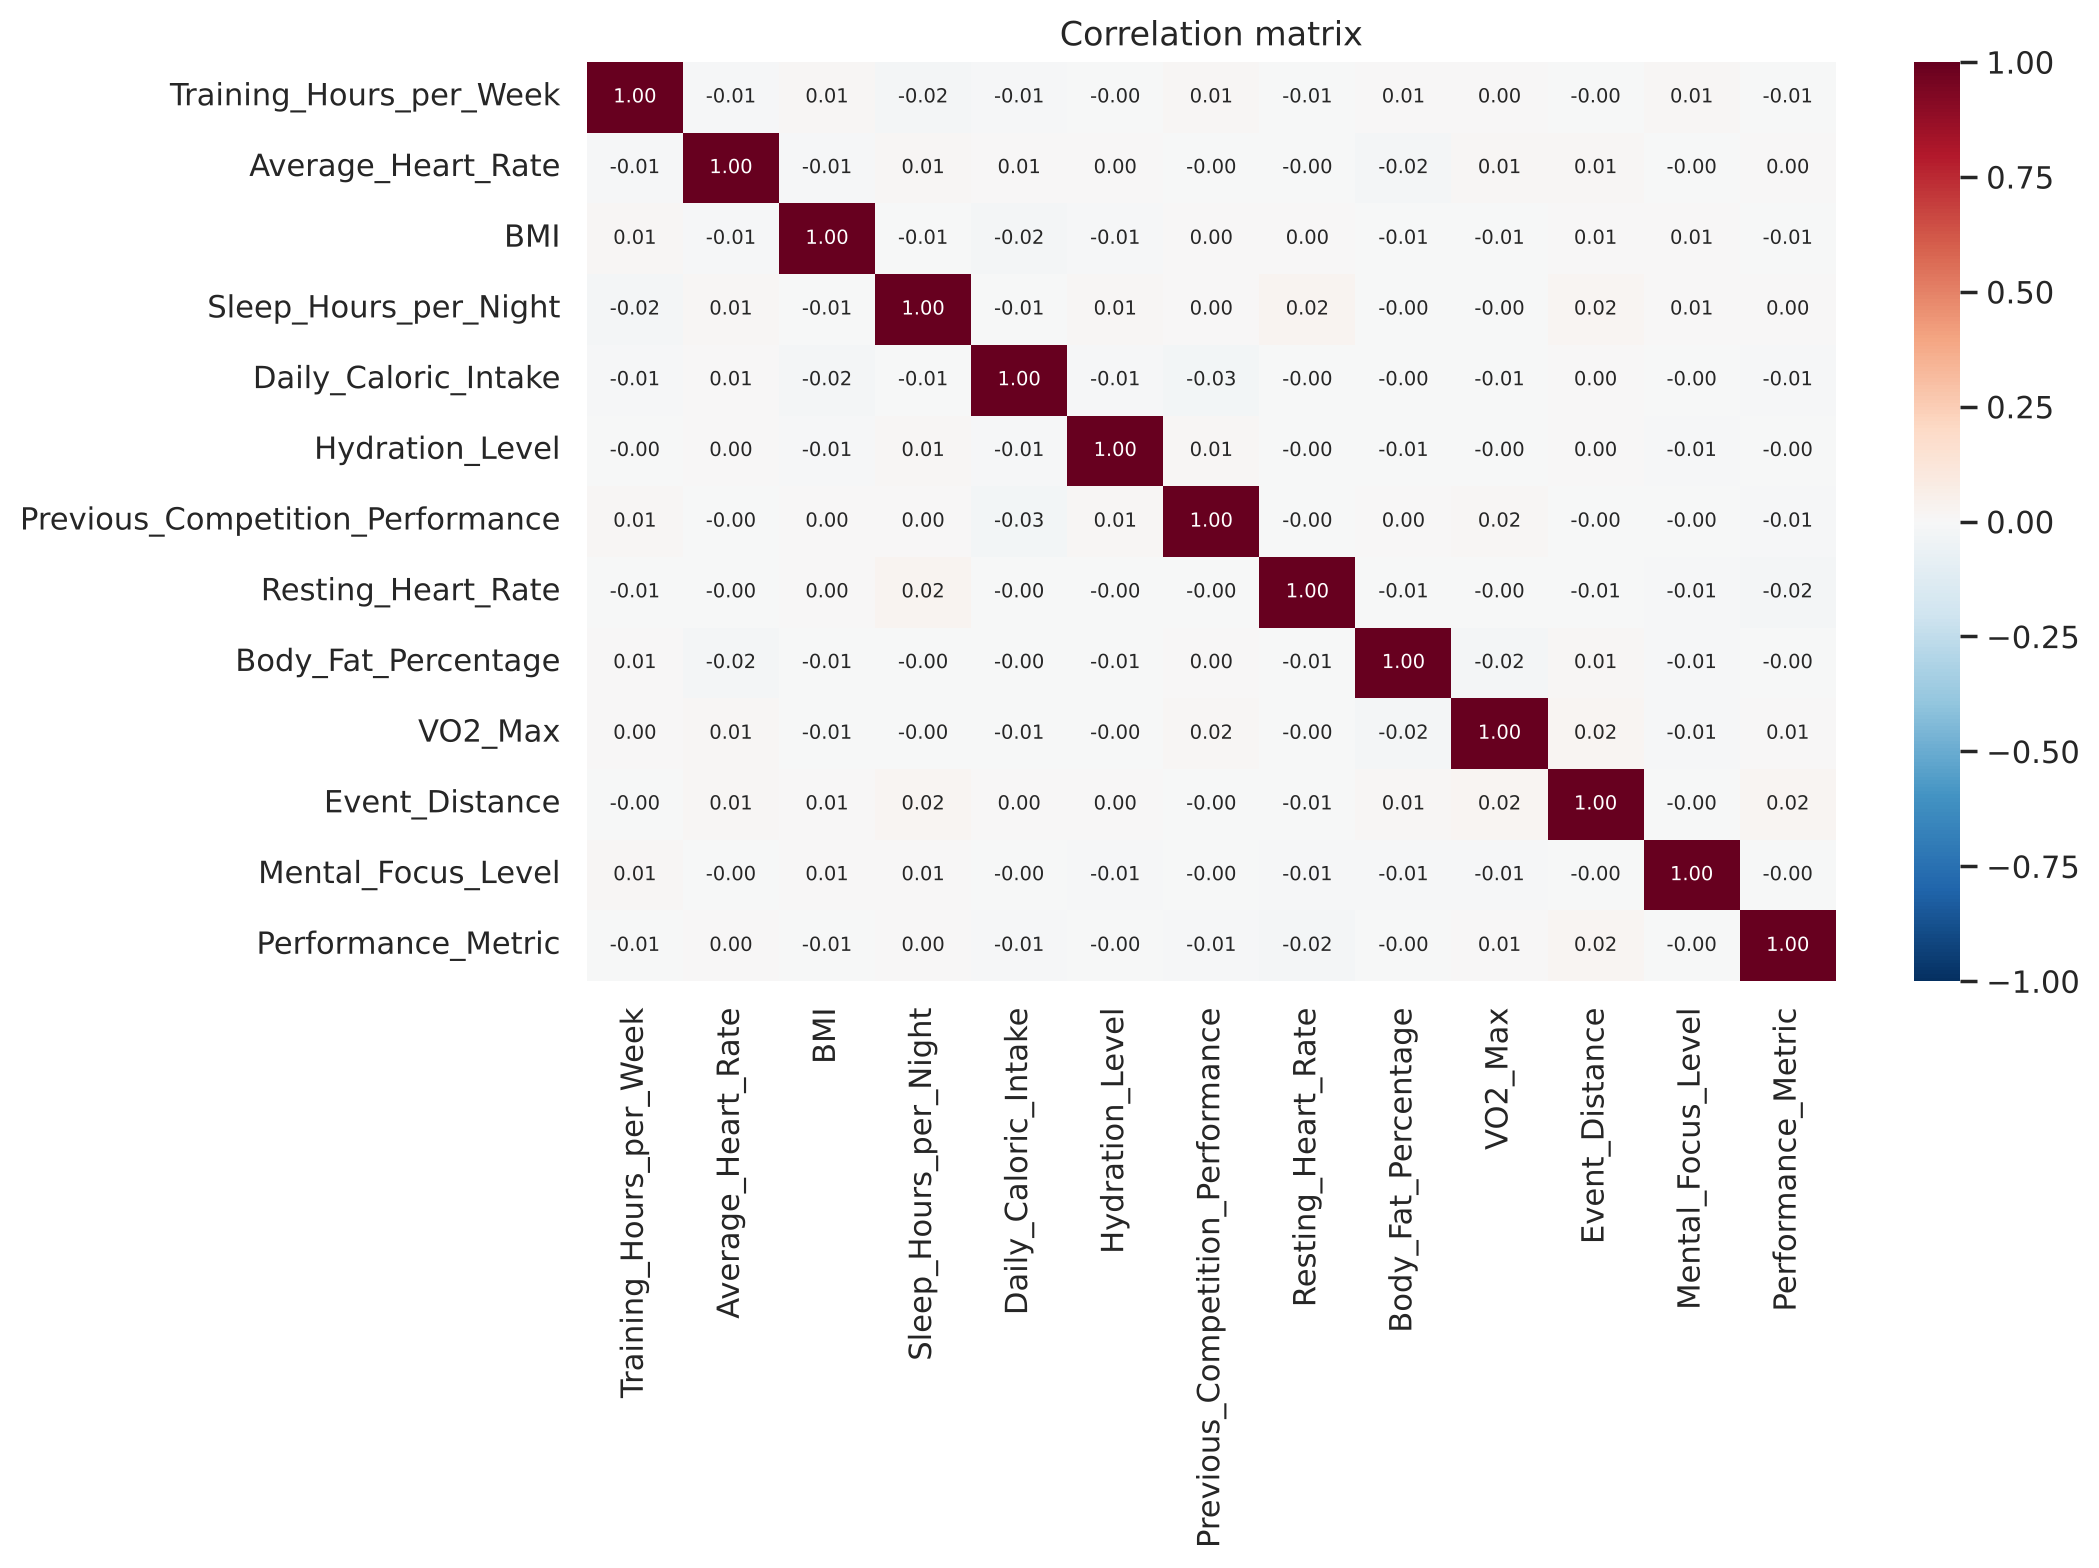

Resting_Heart_Rate                 -0.021936
Previous_Competition_Performance   -0.011435
Daily_Caloric_Intake               -0.009332
BMI                                -0.007545
Training_Hours_per_Week            -0.005339
Mental_Focus_Level                 -0.004298
Body_Fat_Percentage                -0.004175
Hydration_Level                    -0.002134
Average_Heart_Rate                  0.000842
Sleep_Hours_per_Night               0.004091
VO2_Max                             0.006192
Event_Distance                      0.018692
Name: Performance_Metric, dtype: float64

In [7]:
corr = df[num_cols + ['Performance_Metric']].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size':7})
plt.title('Correlation matrix'); plt.tight_layout(); plt.show()
corr['Performance_Metric'].drop('Performance_Metric').sort_values()

**Finding.** The target is almost uniformly spread between 0 and 100, the averages are the same for every sport,
and every feature has |r| < 0.03 with performance. The features carry **almost no linear signal** —
which is typical of synthetic data. Section 4 checks whether non-linear models do better.

## 4. ML model — predicting performance

In [8]:
X = df[num_cols + cat_cols]
y = df['Performance_Metric']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

pre = ColumnTransformer([('num', StandardScaler(), num_cols),
                         ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
models = {
    'Baseline (mean)': DummyRegressor(),
    'Ridge regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
}
rows, fitted = [], {}
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
for name, m in models.items():
    pipe = Pipeline([('pre', pre), ('model', m)]).fit(X_train, y_train)
    p = pipe.predict(X_test)
    rows.append({'Model': name,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': mean_squared_error(y_test, p) ** 0.5,
                 'R2 (test)': r2_score(y_test, p),
                 'R2 (5-fold CV)': cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2').mean()})
    fitted[name] = pipe
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,MAE,RMSE,R2 (test),R2 (5-fold CV)
Model,,,,
Baseline (mean),25.268,29.101,-0.000,-0.001
Ridge regression,25.337,29.172,-0.005,-0.003
Random Forest,25.344,29.227,-0.009,-0.010
XGBoost,25.493,29.409,-0.021,-0.016


Selected model: Ridge regression


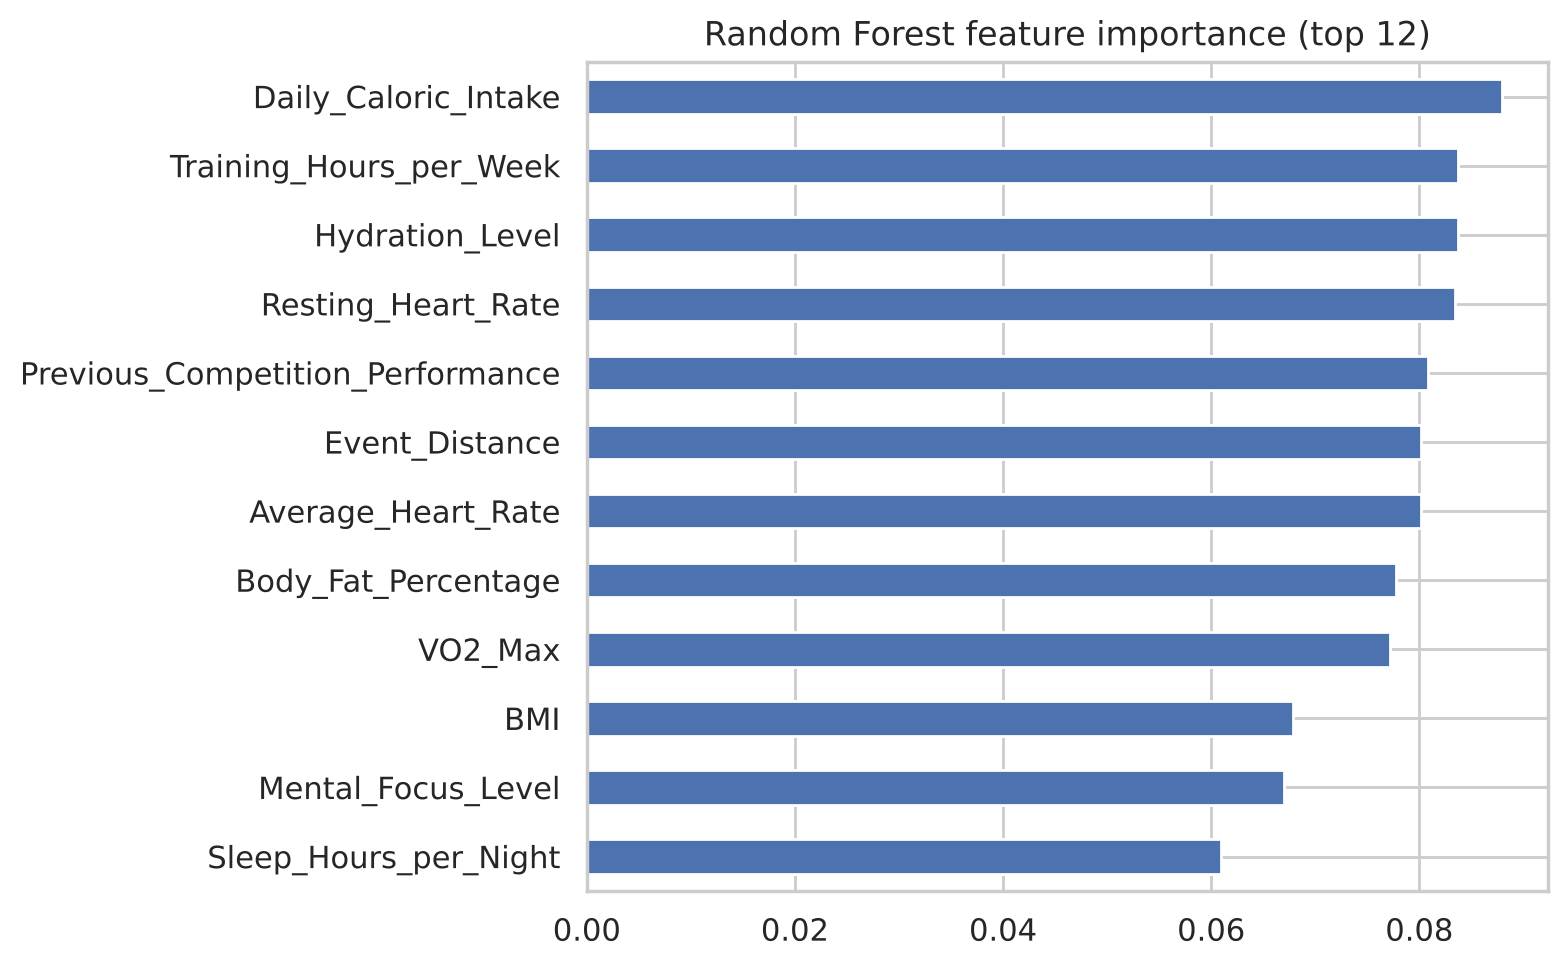

In [9]:
best_name = results.drop('Baseline (mean)')['R2 (5-fold CV)'].idxmax()   # best real model
model = fitted[best_name]
print('Selected model:', best_name)

rf = fitted['Random Forest']
names = rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=names).sort_values().tail(12)
imp.index = imp.index.str.replace('num__', '').str.replace('cat__', '')
imp.plot.barh(figsize=(8, 5), title='Random Forest feature importance (top 12)'); plt.tight_layout(); plt.show()

**Interpretation (important for the report).** No model clearly beats the mean baseline (R² ≈ 0),
so **the ML prediction alone cannot be trusted to make the decision**. This is exactly why a DSS needs more
than a model:
- the DSS reports the model's **uncertainty** next to every prediction (below);
- when the model is uncertain, the **knowledge-driven readiness rules** carry more of the decision weight;
- the **coach always makes the final call** — the system recommends, it does not decide.

This is an honest, defensible finding. It also gives you a strong Reflection point: *data quality limits ML-based decision support*.

In [10]:
# Uncertainty: residual spread on the test set gives an approximate 80% prediction interval
resid = y_test - model.predict(X_test)
q_lo, q_hi = np.quantile(resid, [0.10, 0.90])
print(f'80% prediction interval width ≈ {q_hi - q_lo:.1f} points (on a 0-100 scale)')

80% prediction interval width ≈ 80.4 points (on a 0-100 scale)


## 5. DSS decision layer
The decision model combines **two scores** into one recommendation.

**A. Readiness / risk score (knowledge-driven, 0–100, higher = more risk).**
Weighted rules on recovery and load indicators:

| Criterion | Rule (risk points) | Weight |
|---|---|---|
| Injury history | Major = 1.0, Minor = 0.5, None = 0 | 25 % |
| Sleep | < 6 h = 1.0, 6–7 h = 0.5, ≥ 7 h = 0 | 20 % |
| Training load | High intensity **and** > 30 h/week = 1.0; High or > 30 h = 0.5 | 20 % |
| Resting heart rate | > 85 bpm = 1.0, 75–85 = 0.5 | 15 % |
| Hydration | < 60 % = 1.0, 60–70 % = 0.5 | 10 % |
| Mental focus | < 4 = 1.0, 4–6 = 0.5 | 10 % |

> ⚠️ The thresholds and weights are **design assumptions** for this prototype. In the report, justify each one
> with your academic references (e.g. sleep & recovery, acute:chronic workload and injury risk) or present them
> as values the coaching staff would tune. Do not present them as clinically validated.

**B. Expected performance (model-driven)** — the ML prediction, with its uncertainty.

**Decision rules**

| Condition | Recommendation |
|---|---|
| Risk ≥ 65 | **Rest & medical check** |
| 45 ≤ Risk < 65 | **Reduce load** |
| Risk < 25 and predicted performance in the top 40 % of the squad | **Increase load** |
| Otherwise | **Maintain load** |

If the model's prediction interval is wide, the output is flagged **"Low model confidence — coach review"**.

In [11]:
WEIGHTS = {'injury': .25, 'sleep': .20, 'load': .20, 'rhr': .15, 'hydration': .10, 'focus': .10}

def risk_components(r):
    hi_int, long = r.Training_Intensity == 'High', r.Training_Hours_per_Week > 30
    return {
        'injury':    {'Major': 1, 'Minor': .5}.get(r.Injury_History, 0),
        'sleep':     1 if r.Sleep_Hours_per_Night < 6 else .5 if r.Sleep_Hours_per_Night < 7 else 0,
        'load':      1 if (hi_int and long) else .5 if (hi_int or long) else 0,
        'rhr':       1 if r.Resting_Heart_Rate > 85 else .5 if r.Resting_Heart_Rate >= 75 else 0,
        'hydration': 1 if r.Hydration_Level < 60 else .5 if r.Hydration_Level < 70 else 0,
        'focus':     1 if r.Mental_Focus_Level < 4 else .5 if r.Mental_Focus_Level < 6 else 0,
    }

LABELS = {'injury': 'injury history', 'sleep': 'low sleep', 'load': 'high training load',
          'rhr': 'elevated resting HR', 'hydration': 'low hydration', 'focus': 'low mental focus'}

def recommend(r, pred, interval_width, perf_cut):
    comp = risk_components(r)
    risk = 100 * sum(WEIGHTS[k] * v for k, v in comp.items())
    if risk >= 65:   action = 'Rest & medical check'
    elif risk >= 45: action = 'Reduce load'
    elif risk < 25 and pred >= perf_cut: action = 'Increase load'
    else:            action = 'Maintain load'
    drivers = [LABELS[k] for k, v in sorted(comp.items(), key=lambda kv: -WEIGHTS[kv[0]] * kv[1]) if v > 0][:3]
    return {'Risk_Score': round(risk, 1), 'Predicted_Performance': round(pred, 1),
            'Recommendation': action,
            'Main_Drivers': ', '.join(drivers) if drivers else 'no risk flags',
            'Confidence': 'Low model confidence - coach review' if interval_width > 30 else 'OK'}

width = q_hi - q_lo
preds = model.predict(X)
PERF_CUT = np.quantile(preds, 0.60)   # top 40% of predicted performance
print(f'Performance cut-off for "Increase": {PERF_CUT:.1f}')
dss = pd.DataFrame([recommend(r, p, width, PERF_CUT) for r, p in zip(df.itertuples(), preds)], index=df.index)
out = pd.concat([df[['Athlete_ID', 'Sport_Type']], dss], axis=1)
out.head(10)

Performance cut-off for "Increase": 50.6


,Athlete_ID,Sport_Type,Risk_Score,Predicted_Performance,Recommendation,Main_Drivers,Confidence
0,A754,Running,25.0,51.4,Maintain load,"elevated resting HR, low hydration",Low model confidence - coach review
1,A792,Soccer,37.5,49.8,Maintain load,"injury history, elevated resting HR, low menta...",Low model confidence - coach review
2,A195,Swimming,70.0,47.3,Rest & medical check,"injury history, elevated resting HR, low sleep",Low model confidence - coach review
3,A559,Cycling,35.0,49.4,Maintain load,"low sleep, high training load, low hydration",Low model confidence - coach review
5,A467,Soccer,30.0,50.1,Maintain load,"low sleep, high training load",Low model confidence - coach review
6,A227,Running,50.0,52.8,Reduce load,"injury history, high training load, low hydration",Low model confidence - coach review
7,A296,Running,35.0,52.8,Maintain load,"injury history, low mental focus",Low model confidence - coach review
8,A975,Running,20.0,51.7,Increase load,"high training load, low hydration",Low model confidence - coach review
9,A479,Swimming,50.0,52.2,Reduce load,"injury history, high training load, low mental...",Low model confidence - coach review
10,A750,Soccer,27.5,47.6,Maintain load,"low sleep, elevated resting HR, low hydration",Low model confidence - coach review


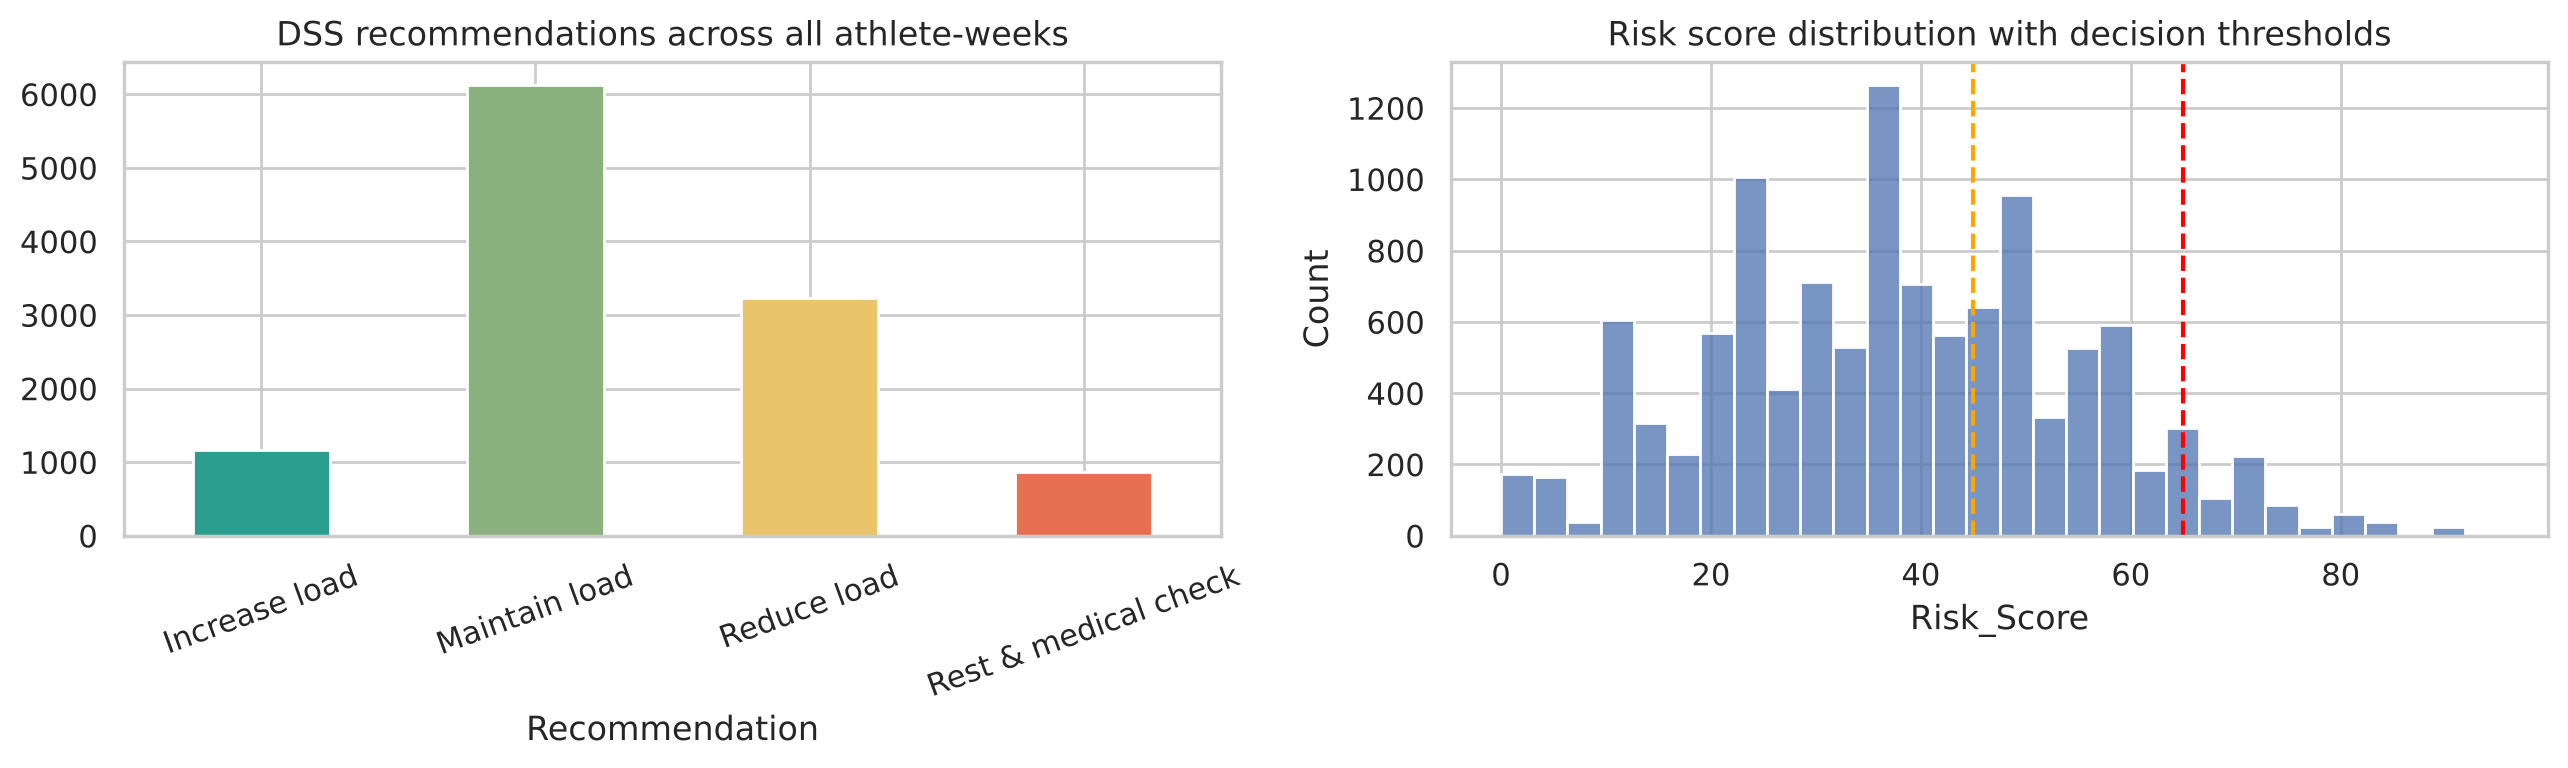

Recommendation
Increase load           10.2
Maintain load           53.8
Reduce load             28.4
Rest & medical check     7.6
Name: proportion, dtype: float64

In [12]:
order = ['Increase load', 'Maintain load', 'Reduce load', 'Rest & medical check']
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
out.Recommendation.value_counts().reindex(order).plot.bar(ax=ax[0], color=['#2a9d8f','#8ab17d','#e9c46a','#e76f51'])
ax[0].set_title('DSS recommendations across all athlete-weeks'); ax[0].tick_params(axis='x', rotation=20)
sns.histplot(out.Risk_Score, bins=30, ax=ax[1]); ax[1].axvline(45, ls='--', c='orange'); ax[1].axvline(65, ls='--', c='red')
ax[1].set_title('Risk score distribution with decision thresholds')
plt.tight_layout(); plt.show()
(out.Recommendation.value_counts(normalize=True).reindex(order) * 100).round(1)

## 6. Scenario evaluation
Four realistic athlete profiles to show how the DSS reasons — use these as the **case study** in the report and the **demo** in the presentation.

In [13]:
base = df[num_cols + cat_cols].median(numeric_only=True).to_dict()
scenarios = pd.DataFrame([
    {**base, 'Sport_Type': 'Running', 'Training_Intensity': 'Medium', 'Injury_History': 'None', 'Altitude_Training': 'None',
     'Sleep_Hours_per_Night': 8.2, 'Resting_Heart_Rate': 58, 'Hydration_Level': 88, 'Mental_Focus_Level': 8.5, 'Training_Hours_per_Week': 18},
    {**base, 'Sport_Type': 'Soccer', 'Training_Intensity': 'High', 'Injury_History': 'Minor', 'Altitude_Training': 'None',
     'Sleep_Hours_per_Night': 6.5, 'Resting_Heart_Rate': 72, 'Hydration_Level': 75, 'Mental_Focus_Level': 6.5, 'Training_Hours_per_Week': 26},
    {**base, 'Sport_Type': 'Swimming', 'Training_Intensity': 'High', 'Injury_History': 'None', 'Altitude_Training': 'High',
     'Sleep_Hours_per_Night': 5.8, 'Resting_Heart_Rate': 80, 'Hydration_Level': 66, 'Mental_Focus_Level': 5.0, 'Training_Hours_per_Week': 34},
    {**base, 'Sport_Type': 'Cycling', 'Training_Intensity': 'High', 'Injury_History': 'Major', 'Altitude_Training': 'None',
     'Sleep_Hours_per_Night': 5.0, 'Resting_Heart_Rate': 92, 'Hydration_Level': 55, 'Mental_Focus_Level': 3.0, 'Training_Hours_per_Week': 38},
], index=['A: Well-recovered runner', 'B: Busy soccer player', 'C: Over-training swimmer', 'D: Injured, exhausted cyclist'])
sp = model.predict(scenarios[num_cols + cat_cols])
pd.DataFrame([recommend(r, p, width, PERF_CUT) for r, p in zip(scenarios.itertuples(), sp)], index=scenarios.index)

,Risk_Score,Predicted_Performance,Recommendation,Main_Drivers,Confidence
A: Well-recovered runner,0.0,51.0,Increase load,no risk flags,Low model confidence - coach review
B: Busy soccer player,32.5,50.6,Maintain load,"injury history, low sleep, high training load",Low model confidence - coach review
C: Over-training swimmer,57.5,49.4,Reduce load,"low sleep, high training load, elevated restin...",Low model confidence - coach review
"D: Injured, exhausted cyclist",100.0,51.7,Rest & medical check,"injury history, low sleep, high training load",Low model confidence - coach review


**How to use this in the report (Evaluation section)**
- Compare the DSS output with what a coach using *intuition only* might decide for A–D.
- **Strengths:** consistent, transparent (shows the main drivers), puts athlete safety first, cheap to run.
- **Limitations:** the ML model has close to zero predictive power on this dataset; the rule thresholds are assumptions;
  the data is cross-sectional (no week-by-week history per athlete), so true workload trends (acute:chronic ratio) cannot be computed.
- **Improvements:** real longitudinal athlete data, wearable inputs (HRV), thresholds calibrated with coaching staff, feedback loop to retrain the model.

## 7. Export

In [14]:
df.to_csv('sports_performance_clean.csv', index=False)
out.to_csv('dss_recommendations.csv', index=False)
results.to_csv('model_comparison.csv')
joblib.dump(model, 'performance_model.joblib')
print('Saved: sports_performance_clean.csv, dss_recommendations.csv, model_comparison.csv, performance_model.joblib')

Saved: sports_performance_clean.csv, dss_recommendations.csv, model_comparison.csv, performance_model.joblib
